In [4]:
from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURACIÓN
# ============================================================

BLOCK_SIZE = 512
META_BLOCK = 99
DATA_START = 100

SD_IMAGE = Path(
    r"C:\Users\LENOVO\Documents\PICS\sdcard.mmc"
)

print("Archivo SD:")
print(SD_IMAGE)

print()
print("¿Existe?", SD_IMAGE.exists())

if SD_IMAGE.exists():
    print("Tamaño:", SD_IMAGE.stat().st_size, "bytes")

Archivo SD:
C:\Users\LENOVO\Documents\PICS\sdcard.mmc

¿Existe? True
Tamaño: 56320 bytes


In [5]:
def read_block(file, block_number, size=512):
    """
    Lee un bloque de la imagen SD.
    """
    
    file.seek(block_number * BLOCK_SIZE)
    
    data = file.read(size)
    
    if len(data) != size:
        raise EOFError(
            f"No se pudo leer el bloque {block_number}"
        )
    
    return data

In [6]:
def read_metadata(path):
    """
    Lee el bloque 99.
    
    Formato utilizado por el PIC:
    
    byte 0 = 'T'
    byte 1 = 'M'
    byte 2 = versión
    byte 4-5 = cantidad de registros
    """
    
    with open(path, "rb") as file:
        
        block = read_block(
            file,
            META_BLOCK
        )
    
    if block[0:3] != b"TM\x01":
        
        raise ValueError(
            "No se encontró la firma TM01 "
            "en el bloque de metadatos."
        )
    
    count = int.from_bytes(
        block[4:6],
        byteorder="little"
    )
    
    return count


# Probar metadatos

try:
    total_registros = read_metadata(
        SD_IMAGE
    )
    
    print(
        "Registros almacenados:",
        total_registros
    )

except Exception as error:
    
    print(
        "ERROR leyendo metadatos:"
    )
    
    print(error)

Registros almacenados: 10


In [7]:
def parse_record(block):
    """
    Interpreta los primeros 12 bytes
    de un bloque de medición.
    """

    # --------------------------------------------------------
    # Verificar firma
    # --------------------------------------------------------
    
    if block[0] != 0xA5:
        return None
    
    if block[1] != 0x01:
        return None
    
    
    # --------------------------------------------------------
    # Número de registro
    # --------------------------------------------------------
    
    numero = int.from_bytes(
        block[2:4],
        byteorder="little"
    )
    
    
    # --------------------------------------------------------
    # Fecha
    # --------------------------------------------------------
    
    anio = block[4]
    mes = block[5]
    dia = block[6]
    
    
    # --------------------------------------------------------
    # Hora
    # --------------------------------------------------------
    
    hora = block[7]
    minuto = block[8]
    segundo = block[9]
    
    
    # --------------------------------------------------------
    # Sensor
    # --------------------------------------------------------
    
    temperatura = block[10]
    humedad = block[11]
    
    
    return {
        "numero": numero,
        "anio": anio,
        "mes": mes,
        "dia": dia,
        "hora": hora,
        "minuto": minuto,
        "segundo": segundo,
        "temperatura": temperatura,
        "humedad": humedad
    }

In [8]:
def read_records(path):
    """
    Lee todos los registros almacenados
    desde el bloque 100 en adelante.
    """

    total = read_metadata(path)
    
    rows = []
    
    
    with open(path, "rb") as file:
        
        for i in range(total):
            
            block_number = DATA_START + i
            
            block = read_block(
                file,
                block_number
            )
            
            record = parse_record(
                block
            )
            
            if record is not None:
                rows.append(record)
    
    
    df = pd.DataFrame(rows)
    
    
    if not df.empty:
        
        # ----------------------------------------------------
        # Convertir año YY a 20YY
        # ----------------------------------------------------
        
        df["fecha_hora"] = pd.to_datetime(
            {
                "year":
                    2000 +
                    df["anio"].astype(int),
                
                "month":
                    df["mes"].astype(int),
                
                "day":
                    df["dia"].astype(int),
                
                "hour":
                    df["hora"].astype(int),
                
                "minute":
                    df["minuto"].astype(int),
                
                "second":
                    df["segundo"].astype(int)
            },
            errors="coerce"
        )
        
        
        df = df.sort_values(
            "numero"
        ).reset_index(drop=True)
    
    
    return total, df


# ============================================================
# EJECUTAR
# ============================================================

total, df = read_records(
    SD_IMAGE
)

print(
    "Registros indicados por la SD:",
    total
)

print(
    "Registros válidos encontrados:",
    len(df)
)

df

Registros indicados por la SD: 10
Registros válidos encontrados: 10


,numero,anio,mes,dia,hora,minuto,segundo,temperatura,humedad,fecha_hora
0,0,26,10,3,12,0,10,27,76,2026-10-03 12:00:10
1,1,26,10,3,12,0,20,27,76,2026-10-03 12:00:20
2,2,26,10,3,12,0,30,27,76,2026-10-03 12:00:30
3,3,26,10,3,12,0,40,27,76,2026-10-03 12:00:40
4,4,26,10,3,12,0,50,27,76,2026-10-03 12:00:50
5,5,26,10,3,12,0,10,28,76,2026-10-03 12:00:10
6,6,26,10,3,12,0,10,28,76,2026-10-03 12:00:10
7,7,26,10,3,12,0,20,28,78,2026-10-03 12:00:20
8,8,26,10,3,12,0,30,33,79,2026-10-03 12:00:30
9,9,26,10,3,12,0,40,33,82,2026-10-03 12:00:40


In [9]:
if df.empty:
    
    print("No hay registros.")
    
else:
    
    display(
        df[
            [
                "numero",
                "fecha_hora",
                "temperatura",
                "humedad"
            ]
        ]
    )

,numero,fecha_hora,temperatura,humedad
0,0,2026-10-03 12:00:10,27,76
1,1,2026-10-03 12:00:20,27,76
2,2,2026-10-03 12:00:30,27,76
3,3,2026-10-03 12:00:40,27,76
4,4,2026-10-03 12:00:50,27,76
5,5,2026-10-03 12:00:10,28,76
6,6,2026-10-03 12:00:10,28,76
7,7,2026-10-03 12:00:20,28,78
8,8,2026-10-03 12:00:30,33,79
9,9,2026-10-03 12:00:40,33,82


In [11]:
import math
import pandas as pd


# ============================================================
# PERCENTIL IGUAL AL DEL PIC
# ============================================================

def percentile_pic(values, percent):
    values = sorted(
        int(v)
        for v in values
    )

    n = len(values)

    if n == 0:
        return None

    index = (
        (n - 1) * percent
    ) // 100

    return values[index]


# ============================================================
# ESTADISTICAS IGUALES A LAS DEL PIC
# ============================================================

def statistics_pic(values):

    values = [
        int(v)
        for v in values
    ]

    n = len(values)

    if n == 0:
        return {}

    # --------------------------------------------------------
    # MEDIA
    # --------------------------------------------------------

    total = sum(values)

    mean = total // n


    # --------------------------------------------------------
    # VARIANZA
    # --------------------------------------------------------

    variance = (
        sum(
            (v - mean) ** 2
            for v in values
        )
        // n
    )


    # --------------------------------------------------------
    # DESVIACION ESTANDAR
    #
    # math.isqrt() hace la raiz entera,
    # igual que la aproximacion que usamos en el PIC.
    # --------------------------------------------------------

    std = math.isqrt(
        variance
    )


    # --------------------------------------------------------
    # RESULTADO
    # --------------------------------------------------------

    return {
        "Count": n,

        "Mean": mean,

        "Std": std,

        "Min": min(values),

        "25%": percentile_pic(
            values,
            25
        ),

        "50%": percentile_pic(
            values,
            50
        ),

        "75%": percentile_pic(
            values,
            75
        ),

        "Max": max(values)
    }


# ============================================================
# COMPROBAR QUE HAYA DATOS
# ============================================================

if df.empty:

    print(
        "No hay registros para calcular estadísticas."
    )

else:

    # --------------------------------------------------------
    # TEMPERATURA
    # --------------------------------------------------------

    temperatura_stats = statistics_pic(
        df["temperatura"]
    )


    # --------------------------------------------------------
    # HUMEDAD
    # --------------------------------------------------------

    humedad_stats = statistics_pic(
        df["humedad"]
    )


    # --------------------------------------------------------
    # CREAR TABLA
    # --------------------------------------------------------

    tabla_estadisticas = pd.DataFrame(
        [
            temperatura_stats,
            humedad_stats
        ],
        index=[
            "Temperatura",
            "Humedad"
        ]
    )


    # --------------------------------------------------------
    # MOSTRAR
    # --------------------------------------------------------

    display(
        tabla_estadisticas
    )

,Count,Mean,Std,Min,25%,50%,75%,Max
Temperatura,10,28,2,27,27,27,28,33
Humedad,10,77,1,76,76,76,76,82


In [12]:
def forecast_pic(df):
    """
    Pronóstico de 6 pasos horarios.
    
    Utiliza la diferencia de las dos últimas
    mediciones, igual que el firmware.
    """
    
    if len(df) < 2:
        
        return pd.DataFrame()
    
    
    previous = df.iloc[-2]
    last = df.iloc[-1]
    
    
    delta_temperature = (
        int(last["temperatura"])
        -
        int(previous["temperatura"])
    )
    
    
    delta_humidity = (
        int(last["humedad"])
        -
        int(previous["humedad"])
    )
    
    
    results = []
    
    
    for step in range(1, 7):
        
        temperature_prediction = (
            int(last["temperatura"])
            +
            delta_temperature * step
        )
        
        
        humidity_prediction = (
            int(last["humedad"])
            +
            delta_humidity * step
        )
        
        
        # ----------------------------------------------------
        # Limites DHT11
        # ----------------------------------------------------
        
        temperature_prediction = max(
            0,
            min(
                50,
                temperature_prediction
            )
        )
        
        
        humidity_prediction = max(
            0,
            min(
                100,
                humidity_prediction
            )
        )
        
        
        results.append(
            {
                "Paso": step,
                "Horas adelante": step,
                "Temperatura °C":
                    temperature_prediction,
                "Humedad %":
                    humidity_prediction
            }
        )
    
    
    return pd.DataFrame(
        results
    )


forecast = forecast_pic(
    df
)

display(
    forecast
)

,Paso,Horas adelante,Temperatura °C,Humedad %
0,1,1,33,85
1,2,2,33,88
2,3,3,33,91
3,4,4,33,94
4,5,5,33,97
5,6,6,33,100


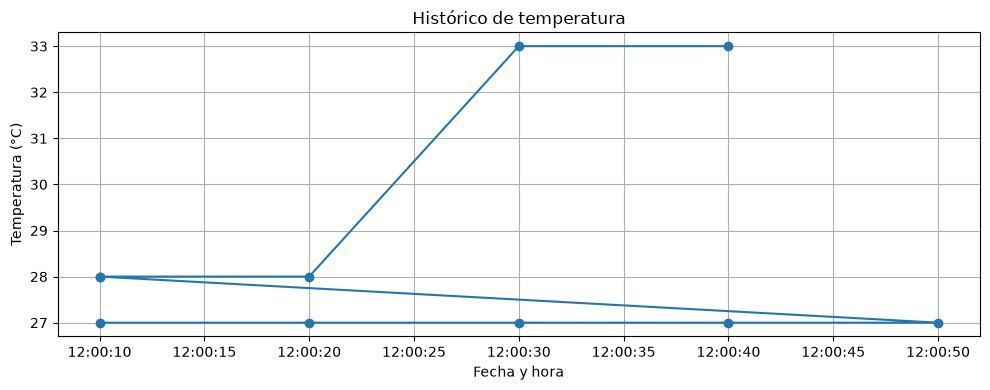

In [13]:
if not df.empty:
    
    plt.figure(
        figsize=(10, 4)
    )
    
    plt.plot(
        df["fecha_hora"],
        df["temperatura"],
        marker="o"
    )
    
    plt.xlabel(
        "Fecha y hora"
    )
    
    plt.ylabel(
        "Temperatura (°C)"
    )
    
    plt.title(
        "Histórico de temperatura"
    )
    
    plt.grid(
        True
    )
    
    plt.tight_layout()
    
    plt.show()

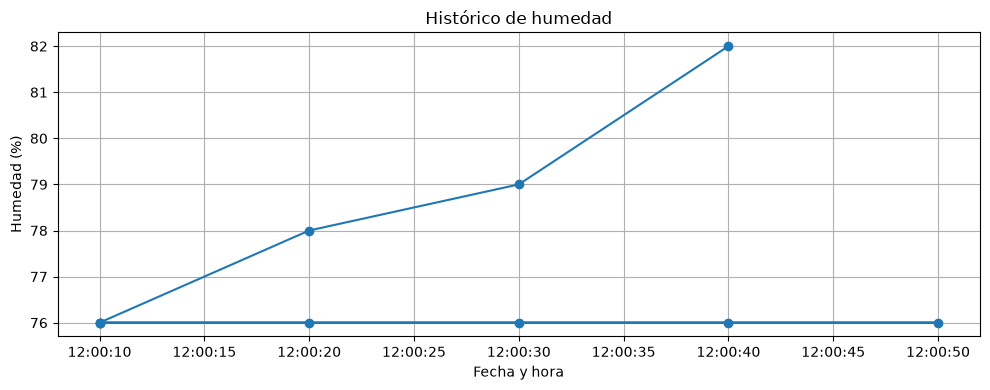

In [14]:
if not df.empty:
    
    plt.figure(
        figsize=(10, 4)
    )
    
    plt.plot(
        df["fecha_hora"],
        df["humedad"],
        marker="o"
    )
    
    plt.xlabel(
        "Fecha y hora"
    )
    
    plt.ylabel(
        "Humedad (%)"
    )
    
    plt.title(
        "Histórico de humedad"
    )
    
    plt.grid(
        True
    )
    
    plt.tight_layout()
    
    plt.show()

In [15]:
if not df.empty:
    
    csv_path = (
        SD_IMAGE.parent /
        "historico_termometro.csv"
    )
    
    
    columnas = [
        "numero",
        "fecha_hora",
        "temperatura",
        "humedad"
    ]
    
    
    df[columnas].to_csv(
        csv_path,
        index=False
    )
    
    
    print(
        "CSV generado correctamente:"
    )
    
    print(
        csv_path
    )

CSV generado correctamente:
C:\Users\LENOVO\Documents\PICS\historico_termometro.csv
